# Uncertainty-aware MGMT prediction from brain MRI — pilot

**Question:** can a simple MRI model predict MGMT promoter methylation in glioblastoma *and* tell us when it is unsure?

**Pipeline**
1. Load one MRI sequence (FLAIR by default) per patient and keep the slices with the most brain tissue.
2. Train a 5-model **deep ensemble** (pre-trained ResNet18, 5-fold cross-validation, split *by patient*).
3. Measure **calibration** (are the probabilities honest?).
4. Use **split conformal prediction** so each patient gets either a confident label or *"uncertain – refer to lab"*.
5. Plot a **risk–coverage curve** (accuracy vs % of patients answered).
6. **Stress-test** with noise, blur and darkening, and check that uncertainty rises.
7. **Runtime monitor** (Mahalanobis + energy OOD scores) that flags unusual scans, tested on the same corruptions.
8. **Mondrian conformal prediction**: per-class coverage compared with standard conformal.
9. **Grad-CAM** heatmaps showing where the model looks.

**Data:** RSNA-MICCAI Brain Tumor Radiogenomic Classification (Kaggle, 2021).

### How to run
**Kaggle (easiest):** New Notebook → *File → Import Notebook* → upload this file → *Add Input* → search the competition name and add it (accept the competition rules first) → *Settings → Accelerator → GPU T4* → turn **Internet on** (for the pre-trained weights) → *Run All*.


## 1. Settings

In [2]:
import os, subprocess

SEQUENCE   = "FLAIR"    # one of: FLAIR, T1w, T1wCE, T2w
N_SLICES   = 12         # slices kept per patient
IMG_SIZE   = 224
N_FOLDS    = 5          # = number of models in the ensemble
EPOCHS     = 6
BATCH_SIZE = 32
LR         = 3e-4
ALPHA      = 0.10       # conformal error rate -> target coverage 90%
SEED       = 42
EXCLUDE    = [109, 123, 709]   # cases flagged by the competition hosts as problematic
COMPETITION = "rsna-miccai-brain-tumor-radiogenomic-classification"

DATA_DIR = f"/kaggle/input/{COMPETITION}"
if not os.path.exists(f"{DATA_DIR}/train_labels.csv"):
    DATA_DIR = f"/kaggle/input/competitions/{COMPETITION}"
OUT_DIR = "/kaggle/working"
print("Data folder:", DATA_DIR, "| labels found:", os.path.exists(f"{DATA_DIR}/train_labels.csv"))

Data folder: /kaggle/input/competitions/rsna-miccai-brain-tumor-radiogenomic-classification | labels found: True


## 2. Imports and reproducibility

In [3]:
import re, json, random, warnings
from glob import glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import cv2
try:
    import pydicom
except ImportError:
    subprocess.run("pip -q install pydicom", shell=True, check=True)
    import pydicom
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score
from joblib import Parallel, delayed
warnings.filterwarnings("ignore")

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(SEED)

DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
NUM_WORKERS = 2
FIG_DIR = f"{OUT_DIR}/figures"; os.makedirs(FIG_DIR, exist_ok=True)
print("Device:", DEVICE, "| torch", torch.__version__)

Device: cuda | torch 2.11.0+cu130


## 3. Load labels and preprocess MRI
For each patient we read the DICOM slices, keep the `N_SLICES` with the largest brain area, normalise intensities and resize. The result is cached so you only do this once.

582 patients | methylated share: 0.526


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    8.5s
[Parallel(n_jobs=4)]: Done  64 tasks      | elapsed:   46.3s
[Parallel(n_jobs=4)]: Done 154 tasks      | elapsed:   56.9s
[Parallel(n_jobs=4)]: Done 280 tasks      | elapsed:  1.2min
[Parallel(n_jobs=4)]: Done 442 tasks      | elapsed:  2.4min
[Parallel(n_jobs=4)]: Done 582 out of 582 | elapsed:  3.4min finished


X: (582, 12, 224, 224) uint8


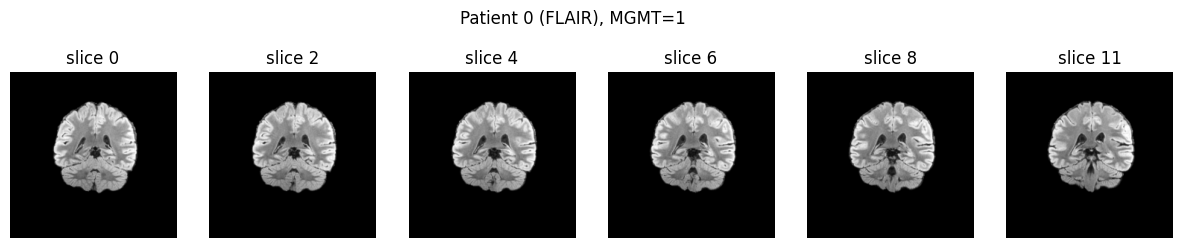

In [4]:
labels = pd.read_csv(f"{DATA_DIR}/train_labels.csv")
labels = labels[~labels.BraTS21ID.isin(EXCLUDE)].reset_index(drop=True)
print(len(labels), "patients | methylated share:", round(labels.MGMT_value.mean(), 3))

def slice_number(path):
    return int(re.search(r"(\d+)\.dcm$", path).group(1))

def load_patient(pid):
    folder = f"{DATA_DIR}/train/{pid:05d}/{SEQUENCE}"
    files = sorted(glob(f"{folder}/*.dcm"), key=slice_number)
    imgs = []
    for f in files:
        try:
            imgs.append(pydicom.dcmread(f).pixel_array.astype(np.float32))
        except Exception:
            pass
    if not imgs:
        return np.zeros((N_SLICES, IMG_SIZE, IMG_SIZE), np.uint8)
    shape = imgs[0].shape
    vol = np.stack([im for im in imgs if im.shape == shape])
    area = (vol > 0.05 * vol.max()).sum(axis=(1, 2))           # brain area per slice
    keep = np.sort(np.argsort(-area)[:N_SLICES])
    keep = np.resize(keep, N_SLICES)                            # repeat if too few slices
    sel = vol[keep]
    hi = np.percentile(sel[sel > 0], 99.5) if (sel > 0).any() else 1.0
    sel = np.clip(sel / (hi + 1e-6), 0, 1)
    sel = np.stack([cv2.resize(s, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA) for s in sel])
    return (sel * 255).astype(np.uint8)

cache = f"{OUT_DIR}/cache_{SEQUENCE}_{N_SLICES}_{IMG_SIZE}.npy"
if os.path.exists(cache):
    X = np.load(cache)
else:
    X = np.stack(Parallel(n_jobs=4, verbose=5)(delayed(load_patient)(p) for p in labels.BraTS21ID))
    np.save(cache, X)
y = labels.MGMT_value.values.astype(int)
print("X:", X.shape, X.dtype)

fig, ax = plt.subplots(1, 6, figsize=(15, 3))
for a, s in zip(ax, np.linspace(0, N_SLICES - 1, 6).astype(int)):
    a.imshow(X[0, s], cmap="gray"); a.axis("off"); a.set_title(f"slice {s}")
plt.suptitle(f"Patient {labels.BraTS21ID[0]} ({SEQUENCE}), MGMT={y[0]}"); plt.show()

## 4. Patient-level split
70% development (5-fold CV → 5 ensemble members), 15% **calibration** (only for conformal prediction), 15% **test** (touched once at the end). Splitting by patient stops slices from the same person leaking between sets.

In [5]:
idx = np.arange(len(y))
dev_idx, hold_idx = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
cal_idx, test_idx = train_test_split(hold_idx, test_size=0.50, stratify=y[hold_idx], random_state=SEED)
print(f"dev {len(dev_idx)} | cal {len(cal_idx)} | test {len(test_idx)}")

dev 407 | cal 87 | test 88


## 5. Dataset, model and training

In [6]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class SliceDataset(Dataset):
    # Every slice is one sample carrying its patient's label; predictions are averaged per patient later.
    def __init__(self, patient_idx, train=False, perturb=None):
        self.items = [(p, s) for p in patient_idx for s in range(X.shape[1])]
        self.train, self.perturb = train, perturb
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        p, s = self.items[i]
        img = torch.from_numpy(X[p, s]).float().div(255.)[None]          # (1,H,W) in [0,1]
        if self.train:
            if random.random() < 0.5: img = img.flip(-1)
            img = TF.rotate(img, random.uniform(-10, 10))
            img = img * random.uniform(0.9, 1.1)
        if self.perturb is not None:
            img = self.perturb(img)
        img = img.clamp(0, 1).repeat(3, 1, 1)
        return (img - MEAN) / STD, torch.tensor(float(y[p])), p

def make_model():
    try:
        m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT)
    except Exception as e:
        print("Could not download pre-trained weights (is Internet on?). Using random init.", e)
        m = torchvision.models.resnet18(weights=None)
    m.fc = nn.Linear(m.fc.in_features, 1)
    return m

@torch.no_grad()
def predict_patients(model, pidx, perturb=None):
    dl = DataLoader(SliceDataset(pidx, perturb=perturb), batch_size=BATCH_SIZE * 2,
                    shuffle=False, num_workers=NUM_WORKERS)
    model.eval(); probs, pids = [], []
    for xb, _, pb in dl:
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(xb.to(DEVICE)).squeeze(1)
        probs.append(torch.sigmoid(logits.float()).cpu()); pids.append(pb)
    s = pd.Series(torch.cat(probs).numpy()).groupby(torch.cat(pids).numpy()).mean()
    return s.loc[pidx].values

def train_one_fold(tr_idx, va_idx, fold):
    seed_everything(SEED + fold)
    model = make_model().to(DEVICE)
    dl = DataLoader(SliceDataset(tr_idx, train=True), batch_size=BATCH_SIZE, shuffle=True,
                    num_workers=NUM_WORKERS, drop_last=True)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * len(dl))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    loss_fn = nn.BCEWithLogitsLoss()
    best = (-1, None, None)
    for ep in range(EPOCHS):
        model.train(); total = 0.0
        for xb, yb, _ in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                loss = loss_fn(model(xb).squeeze(1), yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            total += loss.item() * len(xb)
        p_va = predict_patients(model, va_idx)
        auc = roc_auc_score(y[va_idx], p_va)
        print(f"fold {fold} epoch {ep+1}/{EPOCHS}  loss {total/len(dl.dataset):.4f}  val AUC {auc:.3f}")
        if auc > best[0]:
            best = (auc, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, p_va)
    return best

In [7]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
states, oof = [], np.zeros(len(dev_idx))
for fold, (tr, va) in enumerate(skf.split(dev_idx, y[dev_idx])):
    auc, state, p_va = train_one_fold(dev_idx[tr], dev_idx[va], fold)
    states.append(state); oof[va] = p_va
    print(f"==> fold {fold} best val AUC {auc:.3f}\n")
oof_auc = roc_auc_score(y[dev_idx], oof)
print("Out-of-fold AUC (dev):", round(oof_auc, 3))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 197MB/s]


fold 0 epoch 1/6  loss 0.6458  val AUC 0.584
fold 0 epoch 2/6  loss 0.5564  val AUC 0.630
fold 0 epoch 3/6  loss 0.3923  val AUC 0.615
fold 0 epoch 4/6  loss 0.2353  val AUC 0.623
fold 0 epoch 5/6  loss 0.1248  val AUC 0.592
fold 0 epoch 6/6  loss 0.0668  val AUC 0.578
==> fold 0 best val AUC 0.630

fold 1 epoch 1/6  loss 0.6924  val AUC 0.552
fold 1 epoch 2/6  loss 0.5801  val AUC 0.600
fold 1 epoch 3/6  loss 0.4230  val AUC 0.610
fold 1 epoch 4/6  loss 0.2777  val AUC 0.624
fold 1 epoch 5/6  loss 0.1278  val AUC 0.549
fold 1 epoch 6/6  loss 0.0700  val AUC 0.551
==> fold 1 best val AUC 0.624

fold 2 epoch 1/6  loss 0.6837  val AUC 0.479
fold 2 epoch 2/6  loss 0.5558  val AUC 0.578
fold 2 epoch 3/6  loss 0.4033  val AUC 0.568
fold 2 epoch 4/6  loss 0.2644  val AUC 0.463
fold 2 epoch 5/6  loss 0.1345  val AUC 0.558
fold 2 epoch 6/6  loss 0.0676  val AUC 0.542
==> fold 2 best val AUC 0.578

fold 3 epoch 1/6  loss 0.6350  val AUC 0.510
fold 3 epoch 2/6  loss 0.5599  val AUC 0.661
fold 3 

## 6. Ensemble predictions on calibration and test sets
The ensemble probability is the mean of the 5 models; their **standard deviation** is a measure of disagreement (uncertainty).

In [8]:
_model = make_model().to(DEVICE)
def ensemble_predict(pidx, perturb=None):
    P = []
    for st in states:
        _model.load_state_dict(st)
        P.append(predict_patients(_model, pidx, perturb))
    P = np.stack(P)                       # (n_models, n_patients)
    return P.mean(0), P.std(0)

p_cal, s_cal   = ensemble_predict(cal_idx)
p_test, s_test = ensemble_predict(test_idx)
y_cal, y_test  = y[cal_idx], y[test_idx]
print("Calibration AUC:", round(roc_auc_score(y_cal, p_cal), 3))
print("Test AUC       :", round(roc_auc_score(y_test, p_test), 3))

Calibration AUC: 0.541
Test AUC       : 0.633


## 7. Uncertainty tools: calibration, conformal prediction, risk–coverage
**Split conformal prediction (binary):** on the calibration set, score each patient by `1 − probability given to the true class`. The threshold `q̂` is the adjusted `(1−α)` quantile of these scores. For a new patient, every class whose score is ≤ `q̂` goes in the prediction set. One class → confident answer; both classes → *uncertain, refer to lab*. With exchangeable data, the set contains the true class for ≥ 90% of patients (α = 0.10).

In [9]:
def ece_score(p, y, n_bins=10):
    # Expected calibration error on the positive-class probability.
    bins = np.linspace(0, 1, n_bins + 1); ids = np.clip(np.digitize(p, bins) - 1, 0, n_bins - 1)
    e = 0.0
    for b in range(n_bins):
        m = ids == b
        if m.any():
            e += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(e)

def conformal_threshold(p_cal, y_cal, alpha):
    p_true = np.where(y_cal == 1, p_cal, 1 - p_cal)
    scores = 1 - p_true
    n = len(scores)
    level = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
    return float(np.quantile(scores, level, method="higher"))

def prediction_sets(p, qhat):
    # Column 0 = 'unmethylated' included, column 1 = 'methylated' included.
    return np.stack([p <= qhat, (1 - p) <= qhat], axis=1)

def conformal_report(p, y, qhat):
    sets = prediction_sets(p, qhat)
    size = sets.sum(1)
    covered = sets[np.arange(len(y)), y]
    single = size == 1
    acc = float((sets[single].argmax(1) == y[single]).mean()) if single.any() else float("nan")
    return {"coverage": float(covered.mean()), "confident_share": float(single.mean()),
            "confident_accuracy": acc, "uncertain_share": float((size == 2).mean()),
            "empty_share": float((size == 0).mean())}

def risk_coverage(p, y, confidence):
    order = np.argsort(-confidence)
    correct = ((p >= 0.5).astype(int) == y)[order]
    k = np.arange(1, len(y) + 1)
    return k / len(y), np.cumsum(correct) / k

def aurc(coverage, accuracy):
    # Area under the risk (=1-accuracy) / coverage curve: lower is better.
    return float(np.mean(1 - accuracy))

q-hat = 0.796
            coverage: 0.966
     confident_share: 0.114
  confident_accuracy: 0.700
     uncertain_share: 0.886
         empty_share: 0.000
          ECE (test): 0.132


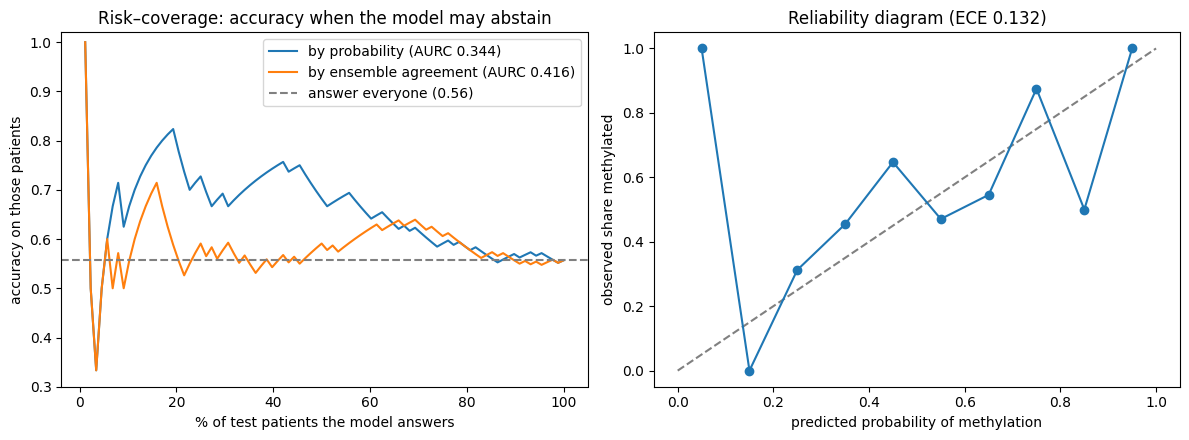

In [10]:
qhat = conformal_threshold(p_cal, y_cal, ALPHA)
conf = conformal_report(p_test, y_test, qhat)
ece_test = ece_score(p_test, y_test)
print(f"q-hat = {qhat:.3f}")
for k, v in conf.items():
    print(f"{k:>20}: {v:.3f}")
print(f"{'ECE (test)':>20}: {ece_test:.3f}")

cov_p, acc_p = risk_coverage(p_test, y_test, np.abs(p_test - 0.5))     # confidence from probability
cov_s, acc_s = risk_coverage(p_test, y_test, -s_test)                   # confidence from ensemble agreement
base_acc = ((p_test >= 0.5).astype(int) == y_test).mean()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(cov_p * 100, acc_p, label=f"by probability (AURC {aurc(cov_p, acc_p):.3f})")
ax[0].plot(cov_s * 100, acc_s, label=f"by ensemble agreement (AURC {aurc(cov_s, acc_s):.3f})")
ax[0].axhline(base_acc, ls="--", c="gray", label=f"answer everyone ({base_acc:.2f})")
ax[0].set_xlabel("% of test patients the model answers"); ax[0].set_ylabel("accuracy on those patients")
ax[0].set_title("Risk–coverage: accuracy when the model may abstain"); ax[0].legend(); ax[0].set_ylim(0.3, 1.02)

bins = np.linspace(0, 1, 11); ids = np.clip(np.digitize(p_test, bins) - 1, 0, 9)
mids = [(bins[b] + bins[b + 1]) / 2 for b in range(10) if (ids == b).any()]
fracs = [y_test[ids == b].mean() for b in range(10) if (ids == b).any()]
ax[1].plot([0, 1], [0, 1], "--", c="gray"); ax[1].plot(mids, fracs, "o-")
ax[1].set_xlabel("predicted probability of methylation"); ax[1].set_ylabel("observed share methylated")
ax[1].set_title(f"Reliability diagram (ECE {ece_test:.3f})")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/risk_coverage_and_calibration.png", dpi=150); plt.show()

## 8. Stress test: does uncertainty rise when images get worse?
We degrade the test images (noise, blur, darkening) and track AUC, ensemble disagreement and the share of patients the conformal step sends to the lab (using the threshold from clean calibration data).

{'perturbation': 'Gaussian noise (σ)', 'level': 0.0, 'auc': np.float64(0.6330227743271222), 'mean_disagreement': 0.19489765167236328, 'referred_to_lab': 0.8863636363636364}
{'perturbation': 'Gaussian noise (σ)', 'level': 0.05, 'auc': np.float64(0.5388198757763976), 'mean_disagreement': 0.22169731557369232, 'referred_to_lab': 0.8977272727272727}
{'perturbation': 'Gaussian noise (σ)', 'level': 0.1, 'auc': np.float64(0.4943064182194617), 'mean_disagreement': 0.16129033267498016, 'referred_to_lab': 0.6363636363636364}
{'perturbation': 'Gaussian noise (σ)', 'level': 0.2, 'auc': np.float64(0.5802277432712215), 'mean_disagreement': 0.12201869487762451, 'referred_to_lab': 0.2954545454545454}
{'perturbation': 'Blur (σ, pixels)', 'level': 0.0, 'auc': np.float64(0.6330227743271222), 'mean_disagreement': 0.19489765167236328, 'referred_to_lab': 0.8863636363636364}
{'perturbation': 'Blur (σ, pixels)', 'level': 1.0, 'auc': np.float64(0.6780538302277432), 'mean_disagreement': 0.15696579217910767, 'ref

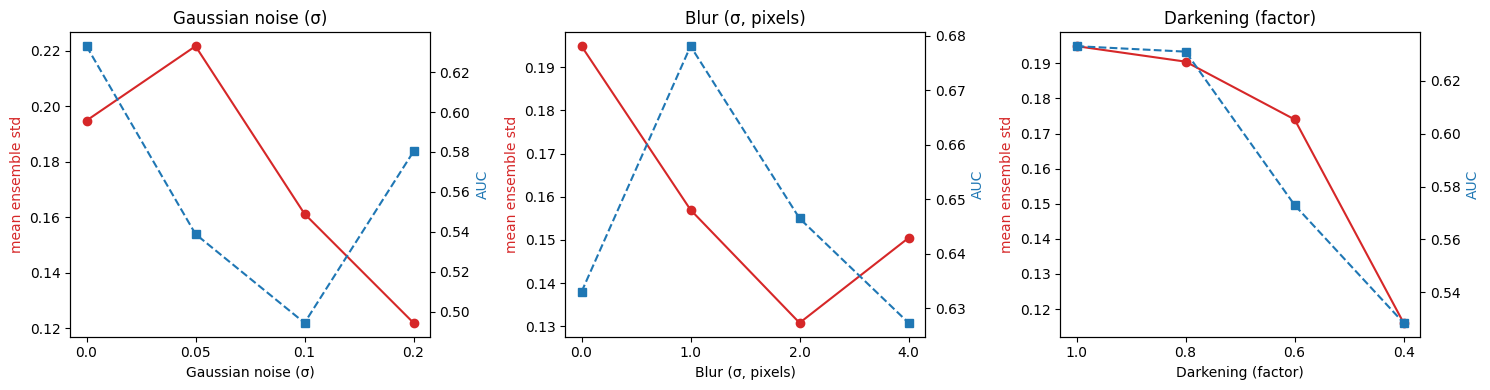

In [11]:
def noise(s):  return lambda img: img + torch.randn_like(img) * s
def blur(s):   return lambda img: TF.gaussian_blur(img, kernel_size=2 * int(round(3 * s)) + 1, sigma=s)
def darken(f): return lambda img: img * f

tests = {"Gaussian noise (σ)": (noise, [0.0, 0.05, 0.10, 0.20]),
         "Blur (σ, pixels)":   (blur,  [0.0, 1.0, 2.0, 4.0]),
         "Darkening (factor)": (darken,[1.0, 0.8, 0.6, 0.4])}
stress = []
for name, (fn, levels) in tests.items():
    for lv in levels:
        clean = (lv == 0.0) or (fn is darken and lv == 1.0)
        p, s = (p_test, s_test) if clean else ensemble_predict(test_idx, fn(lv))
        r = conformal_report(p, y_test, qhat)
        stress.append({"perturbation": name, "level": lv, "auc": roc_auc_score(y_test, p),
                       "mean_disagreement": float(s.mean()), "referred_to_lab": 1 - r["confident_share"]})
        print(stress[-1])
stress = pd.DataFrame(stress)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, (name, g) in enumerate(stress.groupby("perturbation", sort=False)):
    a = ax[i]; a2 = a.twinx()
    a.plot(range(len(g)), g.mean_disagreement, "o-", c="tab:red", label="ensemble disagreement")
    a2.plot(range(len(g)), g.auc, "s--", c="tab:blue", label="AUC")
    a.set_xticks(range(len(g))); a.set_xticklabels(g.level); a.set_xlabel(name)
    a.set_ylabel("mean ensemble std", color="tab:red"); a2.set_ylabel("AUC", color="tab:blue")
    a.set_title(name)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/stress_test.png", dpi=150); plt.show()

## 9. Runtime monitor: can we catch unusual scans *before* trusting the model?
The stress test showed that ensemble disagreement and conformal prediction **do not** react properly to corrupted scans: the models became *more* confident. Here we add two out-of-distribution (OOD) scores that look at the scan itself rather than the model's confidence:

* **Mahalanobis distance** (Lee et al., NeurIPS 2018): how far a patient's deep features are from the features of the training patients. Features from each ResNet18 are averaged over slices, reduced with PCA (fitted on development patients) and scored with a shrinkage (Ledoit–Wolf) Gaussian. Scores from the 5 models are summed.
* **Energy score** (Liu et al., NeurIPS 2020), adapted to our single-logit head by using the symmetric logits [−z/2, +z/2]. For a binary model this is essentially a function of |z|, so we expect it to behave like model confidence. It is included as a deliberate baseline.

The alarm threshold is the 95th percentile of the score on the **calibration** patients (unseen during training), so about 5% of normal scans are expected to raise a false alarm.

In [12]:
from sklearn.decomposition import PCA
from sklearn.covariance import LedoitWolf

N_PCA     = 32      # feature dimensions kept for the Mahalanobis monitor
OOD_QUANT = 0.95    # alarm threshold = this quantile of calibration scores

@torch.no_grad()
def patient_outputs(model, pidx, perturb=None):
    """Per patient: mean penultimate features, mean slice probability, mean slice energy score."""
    body = nn.Sequential(*list(model.children())[:-1])          # ResNet18 up to global average pooling
    dl = DataLoader(SliceDataset(pidx, perturb=perturb), batch_size=BATCH_SIZE * 2,
                    shuffle=False, num_workers=NUM_WORKERS)
    model.eval(); feats, probs, energy, pids = [], [], [], []
    for xb, _, pb in dl:
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            f = body(xb.to(DEVICE)).flatten(1)
            z = model.fc(f).squeeze(1)
        f, z = f.float().cpu(), z.float().cpu()
        feats.append(f); probs.append(torch.sigmoid(z)); pids.append(pb)
        energy.append(-torch.log(2 * torch.cosh(z / 2)))         # energy of logits [-z/2, +z/2]
    pid = torch.cat(pids).numpy()
    f_pat = pd.DataFrame(torch.cat(feats).numpy()).groupby(pid).mean().loc[pidx].values
    p_pat = pd.Series(torch.cat(probs).numpy()).groupby(pid).mean().loc[pidx].values
    e_pat = pd.Series(torch.cat(energy).numpy()).groupby(pid).mean().loc[pidx].values
    return f_pat, p_pat, e_pat

def ensemble_outputs(pidx, perturb=None):
    F_, P_, E_ = [], [], []
    for st in states:
        _model.load_state_dict(st)
        f, p, e = patient_outputs(_model, pidx, perturb)
        F_.append(f); P_.append(p); E_.append(e)
    P_ = np.stack(P_)
    return {"feats": F_, "p": P_.mean(0), "s": P_.std(0), "energy": np.stack(E_).mean(0)}

class MahalanobisMonitor:
    """One PCA + Ledoit-Wolf Gaussian per ensemble member, fitted on development patients."""
    def __init__(self, n_components=N_PCA):
        self.k = n_components
    def fit(self, feats_per_model):
        self.parts = []
        for F_ in feats_per_model:
            pca = PCA(n_components=min(self.k, F_.shape[0] - 1, F_.shape[1]), random_state=SEED).fit(F_)
            self.parts.append((pca, LedoitWolf().fit(pca.transform(F_))))
        return self
    def score(self, feats_per_model):
        # Sum over models of the squared Mahalanobis distance; higher = more unusual.
        return np.sum([lw.mahalanobis(pca.transform(F_))
                       for (pca, lw), F_ in zip(self.parts, feats_per_model)], axis=0)


In [13]:
out_dev  = ensemble_outputs(dev_idx)
out_cal  = ensemble_outputs(cal_idx)
out_test = ensemble_outputs(test_idx)

monitor = MahalanobisMonitor().fit(out_dev["feats"])
maha_cal, maha_test = monitor.score(out_cal["feats"]), monitor.score(out_test["feats"])
energy_cal, energy_test = out_cal["energy"], out_test["energy"]       # higher energy = more unusual

thr = {"mahalanobis": float(np.quantile(maha_cal, OOD_QUANT)),
       "energy":      float(np.quantile(energy_cal, OOD_QUANT))}
print("Alarm thresholds:", thr)
print("False-alarm rate on clean test scans: "
      f"Mahalanobis {np.mean(maha_test > thr['mahalanobis']):.2f}, "
      f"energy {np.mean(energy_test > thr['energy']):.2f} (target ≈ {1 - OOD_QUANT:.2f})")


Alarm thresholds: {'mahalanobis': 228.3975747022597, 'energy': -0.9115319848060608}
False-alarm rate on clean test scans: Mahalanobis 0.02, energy 0.12 (target ≈ 0.05)


### 9.1 Does the monitor catch corrupted scans?
For each corruption we compare the clean test scans (normal) with the corrupted copies of the same patients (unusual):
* **detection AUROC**: 0.5 = no better than chance, 1.0 = perfect separation;
* **alarm rate**: share of corrupted scans above the alarm threshold;
* **referral rate**: share of patients sent to the lab by conformal prediction alone, and by conformal prediction **or** the Mahalanobis alarm.

{'perturbation': 'Gaussian noise (σ)', 'level': 0.0, 'auc': np.float64(0.633), 'mahalanobis_auroc': nan, 'energy_auroc': nan, 'disagreement_auroc': nan, 'mahalanobis_alarm_rate': 0.023, 'energy_alarm_rate': 0.125, 'referred_conformal_only': 0.886, 'referred_conformal_or_monitor': 0.909}
{'perturbation': 'Gaussian noise (σ)', 'level': 0.05, 'auc': np.float64(0.537), 'mahalanobis_auroc': 0.993, 'energy_auroc': 0.492, 'disagreement_auroc': 0.622, 'mahalanobis_alarm_rate': 0.909, 'energy_alarm_rate': 0.148, 'referred_conformal_only': 0.898, 'referred_conformal_or_monitor': 0.989}
{'perturbation': 'Gaussian noise (σ)', 'level': 0.1, 'auc': np.float64(0.492), 'mahalanobis_auroc': 1.0, 'energy_auroc': 0.289, 'disagreement_auroc': 0.376, 'mahalanobis_alarm_rate': 1.0, 'energy_alarm_rate': 0.011, 'referred_conformal_only': 0.636, 'referred_conformal_or_monitor': 1.0}
{'perturbation': 'Gaussian noise (σ)', 'level': 0.2, 'auc': np.float64(0.555), 'mahalanobis_auroc': 1.0, 'energy_auroc': 0.122, '

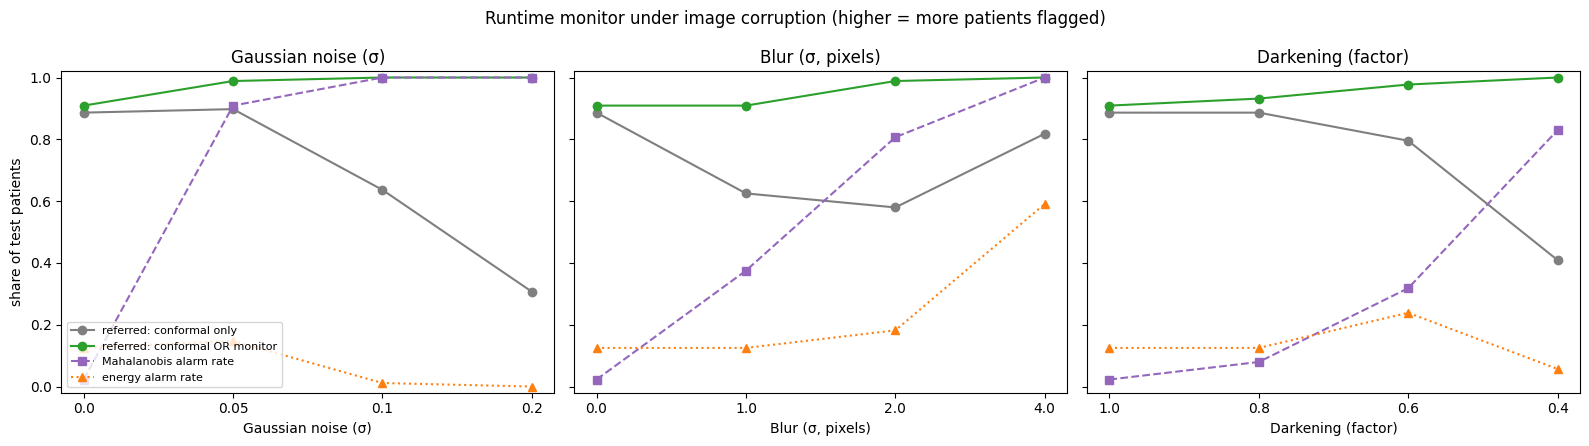

In [14]:
def detection_auroc(score_normal, score_shifted):
    lab = np.r_[np.zeros(len(score_normal)), np.ones(len(score_shifted))]
    return float(roc_auc_score(lab, np.r_[score_normal, score_shifted]))

def conformal_uncertain(p, qhat):
    return prediction_sets(p, qhat).sum(1) != 1          # not exactly one label -> refer

clean_alarm = maha_test > thr["mahalanobis"]
monitor_rows = []
for name, (fn, levels) in tests.items():
    for lv in levels:
        clean = (lv == 0.0) or (fn is darken and lv == 1.0)
        o = out_test if clean else ensemble_outputs(test_idx, fn(lv))
        m = maha_test if clean else monitor.score(o["feats"])
        e = energy_test if clean else o["energy"]
        alarm = m > thr["mahalanobis"]
        unsure = conformal_uncertain(o["p"], qhat)
        monitor_rows.append({
            "perturbation": name, "level": lv, "auc": roc_auc_score(y_test, o["p"]),
            "mahalanobis_auroc": np.nan if clean else detection_auroc(maha_test, m),
            "energy_auroc":      np.nan if clean else detection_auroc(energy_test, e),
            "disagreement_auroc": np.nan if clean else detection_auroc(out_test["s"], o["s"]),
            "mahalanobis_alarm_rate": float(alarm.mean()),
            "energy_alarm_rate": float((e > thr["energy"]).mean()),
            "referred_conformal_only": float(unsure.mean()),
            "referred_conformal_or_monitor": float((unsure | alarm).mean()),
        })
        print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in monitor_rows[-1].items()})
monitor_df = pd.DataFrame(monitor_rows)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for i, (name, g) in enumerate(monitor_df.groupby("perturbation", sort=False)):
    a, xs = ax[i], range(len(g))
    a.plot(xs, g.referred_conformal_only, "o-", c="tab:gray", label="referred: conformal only")
    a.plot(xs, g.referred_conformal_or_monitor, "o-", c="tab:green", label="referred: conformal OR monitor")
    a.plot(xs, g.mahalanobis_alarm_rate, "s--", c="tab:purple", label="Mahalanobis alarm rate")
    a.plot(xs, g.energy_alarm_rate, "^:", c="tab:orange", label="energy alarm rate")
    a.set_xticks(list(xs)); a.set_xticklabels(g.level); a.set_xlabel(name); a.set_title(name)
    a.set_ylim(-0.02, 1.02)
ax[0].set_ylabel("share of test patients"); ax[0].legend(loc="lower left", fontsize=8)
plt.suptitle("Runtime monitor under image corruption (higher = more patients flagged)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/ood_monitor.png", dpi=150); plt.show()


## 10. Mondrian (label-conditional) conformal prediction
Standard split conformal prediction guarantees 90% coverage **on average**, but coverage can be much lower for one group. Mondrian conformal prediction calibrates each group separately, so the guarantee holds **within every group**.

This dataset does not say which hospital each scan came from, so we cannot calibrate per site yet. As a first step we use the true class as the group (label-conditional conformal prediction) and compare per-class coverage. Site-conditional calibration needs a multi-site dataset such as UCSF-PDGM or UPenn-GBM, which is the planned next step.

Note: with about 40 calibration patients per class, the per-class thresholds are themselves noisy.

                  standard  mondrian
coverage_class_0     0.952     0.952
coverage_class_1     0.978     0.978
coverage_overall     0.966     0.966
confident_share      0.114     0.114
uncertain_share      0.886     0.886


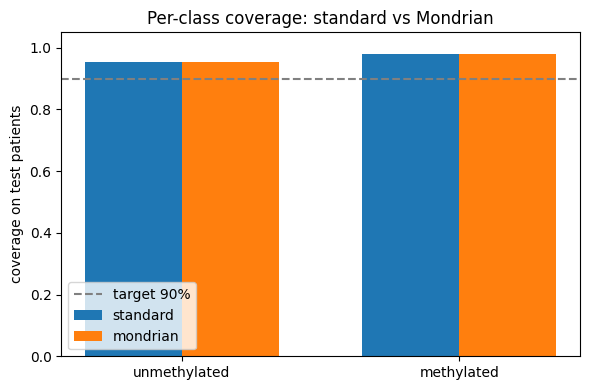

In [15]:
def mondrian_thresholds(p_cal, y_cal, alpha):
    q = {}
    for k in (0, 1):
        pk = p_cal[y_cal == k]
        scores = pk if k == 0 else 1 - pk                   # 1 - probability given to the true class
        n = len(scores)
        level = min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)
        q[k] = float(np.quantile(scores, level, method="higher"))
    return q

def mondrian_sets(p, q):
    return np.stack([p <= q[0], (1 - p) <= q[1]], axis=1)

def per_class_report(sets, y):
    covered = sets[np.arange(len(y)), y]
    size = sets.sum(1)
    rep = {f"coverage_class_{k}": float(covered[y == k].mean()) for k in (0, 1)}
    rep.update({"coverage_overall": float(covered.mean()),
                "confident_share": float((size == 1).mean()),
                "uncertain_share": float((size == 2).mean())})
    return rep

q_mond = mondrian_thresholds(p_cal, y_cal, ALPHA)
mondrian = {"standard": per_class_report(prediction_sets(p_test, qhat), y_test),
            "mondrian": per_class_report(mondrian_sets(p_test, q_mond), y_test),
            "thresholds": {"standard": qhat, "mondrian_class_0": q_mond[0], "mondrian_class_1": q_mond[1]}}
print(pd.DataFrame({k: mondrian[k] for k in ("standard", "mondrian")}).round(3))

fig, ax = plt.subplots(figsize=(6, 4))
xs = np.arange(2); w = 0.35
for j, k in enumerate(("standard", "mondrian")):
    ax.bar(xs + (j - 0.5) * w, [mondrian[k]["coverage_class_0"], mondrian[k]["coverage_class_1"]], w, label=k)
ax.axhline(1 - ALPHA, ls="--", c="gray", label=f"target {1 - ALPHA:.0%}")
ax.set_xticks(xs); ax.set_xticklabels(["unmethylated", "methylated"]); ax.set_ylim(0, 1.05)
ax.set_ylabel("coverage on test patients"); ax.set_title("Per-class coverage: standard vs Mondrian")
ax.legend(); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/mondrian_coverage.png", dpi=150); plt.show()


## 11. Grad-CAM: where does the model look?
Two of the most confident and two of the least confident test patients. Check whether the red areas fall on the tumour.

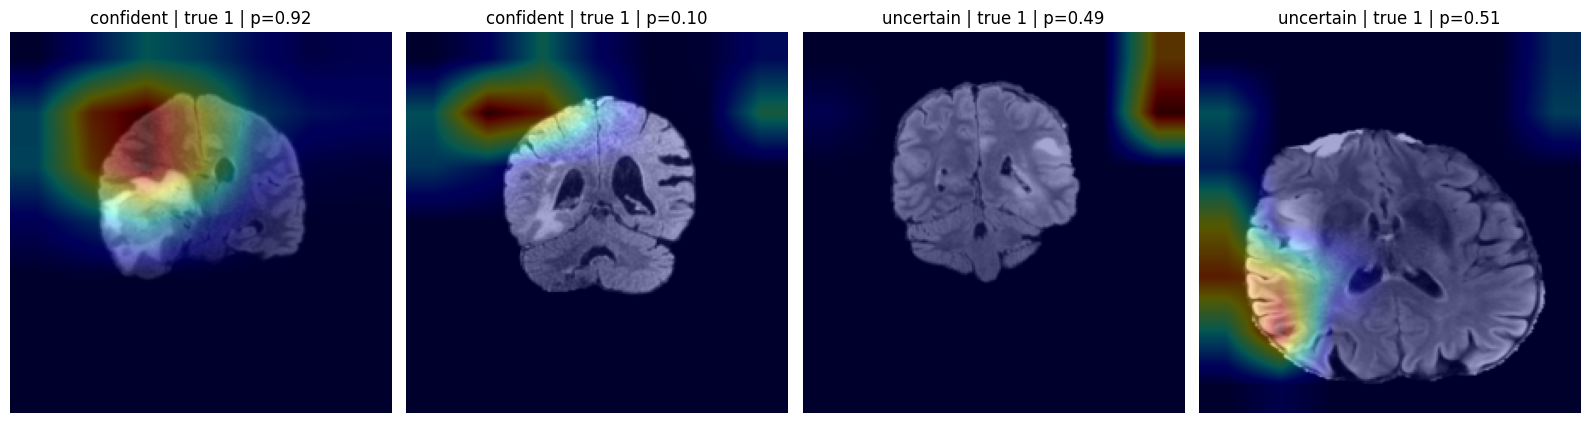

In [16]:
def grad_cam(model, img):
    store = {}
    def fwd_hook(m, i, o):
        store["a"] = o
        o.register_hook(lambda g: store.__setitem__("g", g))
    h = model.layer4.register_forward_hook(fwd_hook)
    model.eval(); model.zero_grad()
    out = model(img[None].to(DEVICE))
    out[0, 0].backward(); h.remove()
    w = store["g"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * store["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=img.shape[1:], mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), torch.sigmoid(out)[0, 0].item()

cam_model = make_model().to(DEVICE); cam_model.load_state_dict(states[0])
order = np.argsort(-np.abs(p_test - 0.5))
picks = list(order[:2]) + list(order[-2:])
ds = SliceDataset(test_idx)
fig, ax = plt.subplots(1, 4, figsize=(16, 4.5))
for a, j in zip(ax, picks):
    s = int(np.argmax((X[test_idx[j]] > 20).sum(axis=(1, 2))))      # slice with most tissue
    img, _, _ = ds[j * N_SLICES + s]
    cam, prob = grad_cam(cam_model, img)
    a.imshow(X[test_idx[j], s], cmap="gray"); a.imshow(cam, cmap="jet", alpha=0.35); a.axis("off")
    tag = "confident" if j in order[:2] else "uncertain"
    a.set_title(f"{tag} | true {y_test[j]} | p={p_test[j]:.2f}")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/gradcam.png", dpi=150); plt.show()

## 12. Save results

In [17]:
results = {
    "settings": {"sequence": SEQUENCE, "n_slices": N_SLICES, "img_size": IMG_SIZE, "n_models": N_FOLDS,
                 "epochs": EPOCHS, "alpha": ALPHA, "seed": SEED},
    "n_patients": {"dev": len(dev_idx), "cal": len(cal_idx), "test": len(test_idx)},
    "auc": {"oof_dev": oof_auc, "cal": roc_auc_score(y_cal, p_cal), "test": roc_auc_score(y_test, p_test)},
    "test_ece": ece_test, "conformal_qhat": qhat, "conformal_test": conf,
    "aurc_test": {"by_probability": aurc(cov_p, acc_p), "by_ensemble_agreement": aurc(cov_s, acc_s)},
    "ood_monitor": {"n_pca": N_PCA, "alarm_quantile": OOD_QUANT, "thresholds": thr,
                    "clean_test_false_alarm": {"mahalanobis": float(np.mean(maha_test > thr["mahalanobis"])),
                                               "energy": float(np.mean(energy_test > thr["energy"]))}},
    "mondrian": mondrian,
}
with open(f"{OUT_DIR}/results.json", "w") as f:
    json.dump(results, f, indent=2, default=float)
stress.to_csv(f"{OUT_DIR}/stress_test.csv", index=False)
monitor_df.to_csv(f"{OUT_DIR}/ood_monitor.csv", index=False)
print(json.dumps(results, indent=2, default=float))
print("\nFigures saved in", FIG_DIR)

{
  "settings": {
    "sequence": "FLAIR",
    "n_slices": 12,
    "img_size": 224,
    "n_models": 5,
    "epochs": 6,
    "alpha": 0.1,
    "seed": 42
  },
  "n_patients": {
    "dev": 407,
    "cal": 87,
    "test": 88
  },
  "auc": {
    "oof_dev": 0.615539199070263,
    "cal": 0.5408271474019088,
    "test": 0.6330227743271222
  },
  "test_ece": 0.13208087711510333,
  "conformal_qhat": 0.7964804768562317,
  "conformal_test": {
    "coverage": 0.9659090909090909,
    "confident_share": 0.11363636363636363,
    "confident_accuracy": 0.7,
    "uncertain_share": 0.8863636363636364,
    "empty_share": 0.0
  },
  "aurc_test": {
    "by_probability": 0.34389219822954786,
    "by_ensemble_agreement": 0.4158126040280025
  },
  "ood_monitor": {
    "n_pca": 32,
    "alarm_quantile": 0.95,
    "thresholds": {
      "mahalanobis": 228.3975747022597,
      "energy": -0.9115319848060608
    },
    "clean_test_false_alarm": {
      "mahalanobis": 0.022727272727272728,
      "energy": 0.125
    }

## 13. Next experiments (do these yourself and record the results)
- Change `SEQUENCE` to `T1wCE` and compare.
- Stack all four sequences as channels instead of one.
- Try more slices (`N_SLICES = 24`) or a 3D model.
- Change `ALPHA` to 0.2 and see how the confident share changes.
- Replace ResNet18 with EfficientNet-B0.

**Limitations to state honestly:** single MRI sequence, 2D slices, one public dataset, small calibration/test sets (~85 patients each), so all numbers have wide uncertainty.